### Алгоритмы Actor-Critic

$$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \frac{1}{1 - \gamma} \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ Q^{\pi_{\boldsymbol{\theta}}}(s, a) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right].
$$

> **Теорема о совместимой функции ценности (Compatible Function Approximation Theorem)**
> 
> Пусть аппроксиматор критика $Q(s, a; \boldsymbol{\varphi})$, где $\boldsymbol{\varphi} \in \mathbb{R}^p$, удовлетворяет двум условиям:
> 
> 1. Условие структурной совместимости (Compatibility Condition)
>    $$
    \nabla_{\boldsymbol{\varphi}} Q(s, a; \boldsymbol{\varphi}) = \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}).
    $$
> 2. Условие согласованности по минимуму среднеквадратичной ошибки (Mean-Squared Error Minimum)
    $$
    \boldsymbol{\varphi}^* = \underset{\boldsymbol{\varphi} \in \mathbb{R}^p}{\operatorname{argmin}} \, \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ \left( Q^{\pi_{\boldsymbol{\theta}}}(s, a) - Q(s, a; \boldsymbol{\varphi}) \right)^2 \right].
    $$
> Тогда замена истинной функции $Q^{\pi_{\boldsymbol{\theta}}}(s, a)$ на аппроксимацию $Q(s, a; \boldsymbol{\varphi}^*)$ не вносит ошибки в вычисление градиента стратегии:
> $$
    \nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \frac{1}{1 - \gamma} \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ Q(s, a; \boldsymbol{\varphi}^*) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right].
    $$
> 
> **Доказательство**
> 
> В точке минимума $\boldsymbol{\varphi}^*$:
> $$
\nabla_{\boldsymbol{\varphi}} \left. \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, a \sim \pi_{\boldsymbol{\theta}}} \left[ \frac{1}{2} \left( Q^{\pi_{\boldsymbol{\theta}}}(s, a) - Q(s, a; \boldsymbol{\varphi}) \right)^2 \right] \right|_{\boldsymbol{\varphi} = \boldsymbol{\varphi}^*} = \boldsymbol{0}.
$$
> Вносим градиент под знак математического ожидания:
> $$
\mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ \left( Q^{\pi_{\boldsymbol{\theta}}}(s, a) - Q(s, a; \boldsymbol{\varphi}^*) \right) \nabla_{\boldsymbol{\varphi}} \left. Q(s, a; \boldsymbol{\varphi}) \right|_{\boldsymbol{\varphi} = \boldsymbol{\varphi}^*} \right] = \mathbf{0}.
$$
> Подставим в полученное тождество первое условие теоремы:
> $$
\mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ \left( Q^{\pi_{\boldsymbol{\theta}}}(s, a) - Q(s, a; \boldsymbol{\varphi}^*) \right) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right] = \mathbf{0}.
$$
> В силу линейности оператора математического ожидания
> $$
\mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ Q^{\pi_{\boldsymbol{\theta}}}(s, a) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right] = \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ Q(s, a; \boldsymbol{\varphi}^*) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right].
$$
> Умножение обеих частей на скалярную константу $1/(1 - \gamma)$ завершает доказательство.


1. Линейный вид совместимого аппроксиматора
    $$
    Q(s, a; \boldsymbol{\varphi}) = \boldsymbol{\varphi}^T \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) + b(s),
    $$
2. Размерность вектора весов совместимого критика должна совпадать с размерностью вектора параметров актора: $\dim(\boldsymbol{\varphi}) = \dim(\boldsymbol{\theta})$.
3. В современных алгоритмах глубокого RL критик параметризуется произвольной нелинейной нейросетью, поэтому условия совместимости нарушаются.

> **Оценка ошибки для несовместимого критика**
>
> При одинаковом распределении состояний и действий в точном и приближённом градиентах разность градиентов имеет вид
> $$
\Delta= \hat\nabla_{\boldsymbol{\theta}}J- \nabla_{\boldsymbol{\theta}}J = \frac{1}{1-\gamma}\mathbb E[\left(Q(s,a;\boldsymbol{\varphi})-Q^\pi(s,a)\right)\nabla_{\boldsymbol{\theta}} \ln\pi(a\mid s;\boldsymbol{\theta})].
$$
> Пусть критик приближает $Q^\pi$ со среднеквадратичной ошибкой
> $$
\varepsilon = \sqrt{\mathbb{E}[(Q(s,a;\boldsymbol{\varphi}) - Q^\pi(s,a))^2]}.
$$
> Применим неравенство Коши — Шварца:
>$$
\begin{aligned}
\|\Delta\|_2 &= \frac{1}{1-\gamma} \left\|\mathbb E[\left(Q(s,a;\boldsymbol{\varphi})-Q^\pi(s,a)\right)\nabla_{\boldsymbol{\theta}} \ln\pi(a\mid s;\boldsymbol{\theta})]\right\|_2 \\
&\leqslant \frac{1}{1-\gamma} \mathbb E[|Q(s,a;\boldsymbol{\varphi})-Q^\pi(s,a)| \|\nabla_{\boldsymbol{\theta}} \ln\pi(a\mid s;\boldsymbol{\theta}\|_2] \\
&\leqslant \frac{1}{1-\gamma} \sqrt{\mathbb E[\left(Q(s,a;\boldsymbol{\varphi})-Q^\pi(s,a)\right)^2]} \sqrt{\mathbb E[\|\nabla_{\boldsymbol{\theta}} \ln\pi(a\mid s;\boldsymbol{\theta})\|_2^2]} \\
&= \frac{\varepsilon}{1-\gamma} \sqrt{\mathbb E[\|\nabla_{\boldsymbol{\theta}} \ln\pi(a\mid s;\boldsymbol{\theta})\|_2^2]}.
\end{aligned}
$$

$$
L(\boldsymbol{\psi}, \boldsymbol{\theta}, \boldsymbol{\varphi}) = L_{\pi}(\boldsymbol{\psi}, \boldsymbol{\theta}) + c_V L_V(\boldsymbol{\psi}, \boldsymbol{\varphi}) - c_H L_{H}(\boldsymbol{\psi}, \boldsymbol{\theta}),
$$
где:

1. **Потери стратегии (Policy Loss):**
   $$
  L_{\pi}(\boldsymbol{\psi}, \boldsymbol{\theta}) = -\frac{1}{B} \sum_{i=1}^B \hat{A}_i \, \ln \pi(a_i \mid s_i; \boldsymbol{\psi}, \boldsymbol{\theta}),
  $$
   где $\hat{A}_i$ — вычисленная оценка преимущества (например, с помощью GAE).
2. **Потери функции ценности (Value Loss):**
   $$
  L_{V}(\boldsymbol{\psi}, \boldsymbol{\varphi}) = \frac{1}{B} \sum_{i=1}^B \frac{1}{2} \left( y_i - V(s_i; \boldsymbol{\psi},  \boldsymbol{\varphi}) \right)^2,
  $$
  где $y_i = \hat{A}_i + V(s_i; \boldsymbol{\psi}_{\text{old}}, \boldsymbol{\varphi}_{\text{old}})$ — фиксированное целевое значение.
3. **Энтропийные потери (Entropy Loss):**
   $$
  L_{H}(\boldsymbol{\psi}, \boldsymbol{\theta}) = \frac{1}{B} \sum_{i=1}^B H(\pi(\cdot \mid s_i; \boldsymbol{\psi}, \boldsymbol{\theta})).
  $$
4. $c_V, c_H > 0$ — весовые коэффициенты балансировки компонент.

#### One-Step Actor-Critic

<img src="images/one-step_actor-critic.png" width="40%" alt="one-step_actor-critic">

#### Asynchronous Advantage Actor-Critic (A3C)

<img src="images/a2c_.webp" width="40%" alt="a2c_">

<img src="images/a2c.png" width="50%" alt="a2c">

In [1]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

%config InlineBackend.figure_format = 'svg'

In [2]:
# =====================================================================
# Actor-Critic
# =====================================================================
GAMMA = 0.99
LR = 1e-3
MAX_EPISODES = 1000
TARGET_SCORE = 495
# Коэффициенты функции потерь
C_VAL = 0.05
C_ENT = 0.005


class ActorCritic(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        super().__init__()
        # Backbone
        self.backbone = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU()
        )
        # Actor: action logits
        self.actor_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )
        # Critic: V(s)
        self.critic_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x: torch.Tensor):
        features = self.backbone(x)
        return self.actor_head(features), self.critic_head(features)



env = gym.make("CartPole-v1")
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

model = ActorCritic(state_dim, action_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# Буферы для метрик и лоссов
episode_rewards = []
moving_averages = []
total_losses = []
actor_losses = []
critic_losses = []
entropy_losses = []

Episode 100/1000 | Avg Reward (20):  49.1 | Loss:   0.59 [Actor:   0.00, 0.5*Critic:   0.59, 0.01*Ent: 0.003]
Episode 200/1000 | Avg Reward (20): 104.8 | Loss:   1.08 [Actor:  -0.01, 0.5*Critic:   1.09, 0.01*Ent: 0.003]
Episode 300/1000 | Avg Reward (20): 288.6 | Loss:   1.20 [Actor:  -0.02, 0.5*Critic:   1.23, 0.01*Ent: 0.003]
Episode 400/1000 | Avg Reward (20): 179.8 | Loss:   1.47 [Actor:  -0.01, 0.5*Critic:   1.48, 0.01*Ent: 0.003]
Episode 500/1000 | Avg Reward (20): 321.3 | Loss:   1.06 [Actor:  -0.01, 0.5*Critic:   1.07, 0.01*Ent: 0.003]
Episode 547/1000 | Avg Reward (20): 496.5 | Loss:   0.72 [Actor:  -0.00, 0.5*Critic:   0.73, 0.01*Ent: 0.003]

Environment solved in episode 547! Final moving average reward: 496.5


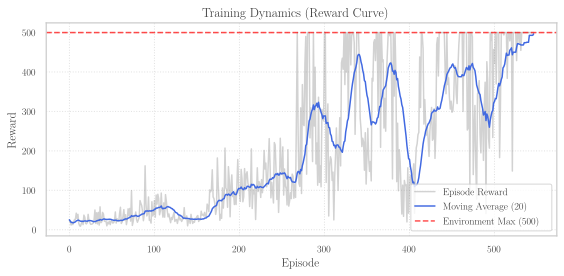

In [3]:
for ep in range(1, MAX_EPISODES + 1):
    state, _ = env.reset()
    done = False
    
    log_probs = []
    values = []
    rewards = []
    entropies = []
    ep_reward = 0.0

    while not done:
        state_t = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
        logits, value = model(state_t)
        
        dist = Categorical(logits=logits)
        action = dist.sample()
        
        next_state, reward, term, trunc, _ = env.step(action.item())
        done = term or trunc
        
        log_probs.append(dist.log_prob(action))
        values.append(value)
        rewards.append(reward)
        entropies.append(dist.entropy())
        
        ep_reward += reward
        state = next_state

    # G_t
    returns = []
    R = 0.0
    for r in reversed(rewards):
        R = r + GAMMA * R
        returns.insert(0, R)
        
    returns = torch.tensor(returns, dtype=torch.float32).unsqueeze(1)
    values = torch.cat(values)
    log_probs = torch.stack(log_probs)
    entropies = torch.cat(entropies)

    # A(s, a) = G_t - V(s)
    advantages = returns - values
    # Normalize
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    # Policy Loss (without advantage)
    actor_loss = -(log_probs * advantages.detach()).mean()
    # Value Loss
    critic_loss = F.smooth_l1_loss(values, returns)
    # Entropy Term
    mean_entropy = entropies.mean()

    # Loss
    loss = actor_loss + C_VAL * critic_loss - C_ENT * mean_entropy

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
    optimizer.step()

    episode_rewards.append(ep_reward)
    avg_score = np.mean(episode_rewards[-20:])
    moving_averages.append(avg_score)

    total_losses.append(loss.item())
    actor_losses.append(actor_loss.item())
    critic_losses.append((C_VAL * critic_loss).item())
    entropy_losses.append((C_ENT * mean_entropy).item())

    if ep % 100 == 0 or avg_score >= TARGET_SCORE:
        mean_tot_loss = np.mean(total_losses[-20:])
        mean_act_loss = np.mean(actor_losses[-20:])
        mean_crt_loss = np.mean(critic_losses[-20:])
        mean_ent_term = np.mean(entropy_losses[-20:])

        print(
            f"Episode {ep:3d}/{MAX_EPISODES} | "
            f"Avg Reward (20): {avg_score:5.1f} | "
            f"Loss: {mean_tot_loss:6.2f} "
            f"[Actor: {mean_act_loss:6.2f}, "
            f"0.5*Critic: {mean_crt_loss:6.2f}, "
            f"0.01*Ent: {mean_ent_term:5.3f}]"
        )

    if avg_score >= TARGET_SCORE:
        print(f"\nEnvironment solved in episode {ep}! Final moving average reward: {avg_score:.1f}")
        break

env.close()

# График обучения
fig_reward, ax_reward = plt.subplots(figsize=(8, 4))

ax_reward.plot(episode_rewards, alpha=0.35, color='gray', label=r'Episode Reward')
ax_reward.plot(moving_averages, color='royalblue', linewidth=1.5, label=r'Moving Average (20)')
ax_reward.axhline(500, color='red', linestyle='--', alpha=0.7, label=r'Environment Max (500)')
ax_reward.set_title(r'Training Dynamics (Reward Curve)', fontsize=13, fontweight='bold')
ax_reward.set_xlabel(r'Episode')
ax_reward.set_ylabel(r'Reward')
ax_reward.grid(True, linestyle=':', alpha=0.6)
ax_reward.legend(loc='lower right')

plt.tight_layout()
plt.show()

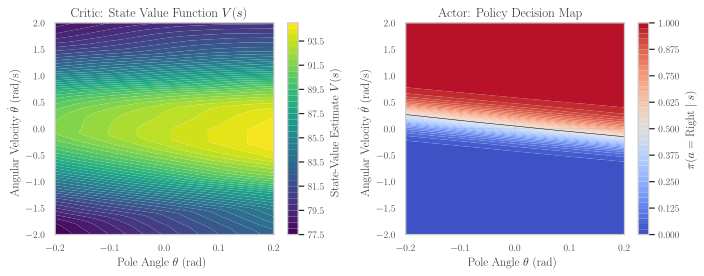

In [4]:
# Визуализация аппроксимаций V(s) и pi(a|s).
# Формируем двумерную сетку на проекции фазового пространства (угол и угловая скорость)
# Фиксируем позицию тележки x = 0 и скорость v = 0.
# Угол шеста от -0.20 до +0.20 рад ~ +-12 градусов, угловую скорость от -2.0 до +2.0 рад/с.
theta_vals = np.linspace(-0.20, 0.20, 120)
theta_dot_vals = np.linspace(-2.0, 2.0, 120)
Theta, Theta_dot = np.meshgrid(theta_vals, theta_dot_vals)

grid_states = np.zeros((Theta.size, 4), dtype=np.float32)
grid_states[:, 2] = Theta.ravel()      # угол шеста
grid_states[:, 3] = Theta_dot.ravel()  # угловая скорость

grid_tensor = torch.as_tensor(grid_states, dtype=torch.float32)

model.eval()
with torch.no_grad():
    logits, values = model(grid_tensor)
    # Вероятность действия 1 (толкнуть тележку вправо)
    probs = F.softmax(logits, dim=-1)[:, 1].numpy()
    values = values.squeeze(-1).numpy()

V_grid = values.reshape(Theta.shape)
Pi_grid = probs.reshape(Theta.shape)

fig_maps, axes_maps = plt.subplots(1, 2, figsize=(10, 4))

# Карта ценности Критика V(s)
c1 = axes_maps[0].contourf(Theta, Theta_dot, V_grid, levels=40, cmap='viridis')
fig_maps.colorbar(c1, ax=axes_maps[0], label='State-Value Estimate $V(s)$')
axes_maps[0].set_title(r'Critic: State Value Function $V(s)$', fontsize=13)
axes_maps[0].set_xlabel(r'Pole Angle $\theta$ (rad)')
axes_maps[0].set_ylabel(r'Angular Velocity $\dot{\theta}$ (rad/s)')

# Карта решений Актора P(Action = Push Right)
c2 = axes_maps[1].contourf(Theta, Theta_dot, Pi_grid, levels=40, cmap='coolwarm', vmin=0.0, vmax=1.0)
fig_maps.colorbar(c2, ax=axes_maps[1], label=r'$\pi(a = \mathrm{Right} \mid s)$')
axes_maps[1].contour(Theta, Theta_dot, Pi_grid, levels=[0.5], colors='black', linewidths=0.5)  # Граница 50%
axes_maps[1].set_title(r'Actor: Policy Decision Map', fontsize=13)
axes_maps[1].set_xlabel(r'Pole Angle $\theta$ (rad)')
axes_maps[1].set_ylabel(r'Angular Velocity $\dot{\theta}$ (rad/s)')

plt.tight_layout()
plt.show()

Update 100/1000 | Avg Reward (20): 135.9 | Loss:   0.64 [Actor:   0.01, 0.05 * Critic:   0.63, -0.002 * Ent: 0.001]
Update 200/1000 | Avg Reward (20):  93.6 | Loss:   0.57 [Actor:  -0.02, 0.05 * Critic:   0.59, -0.002 * Ent: 0.001]
Update 300/1000 | Avg Reward (20): 261.6 | Loss:   0.50 [Actor:   0.00, 0.05 * Critic:   0.49, -0.002 * Ent: 0.001]
Update 400/1000 | Avg Reward (20):  59.6 | Loss:   0.47 [Actor:  -0.00, 0.05 * Critic:   0.47, -0.002 * Ent: 0.001]
Update 500/1000 | Avg Reward (20): 472.4 | Loss:   0.13 [Actor:  -0.03, 0.05 * Critic:   0.15, -0.002 * Ent: 0.001]
Update 502/1000 | Avg Reward (20): 496.9 | Loss:   0.13 [Actor:  -0.03, 0.05 * Critic:   0.16, -0.002 * Ent: 0.001]

A2C успешно решил среду на обновлении 502! Средняя награда: 496.9


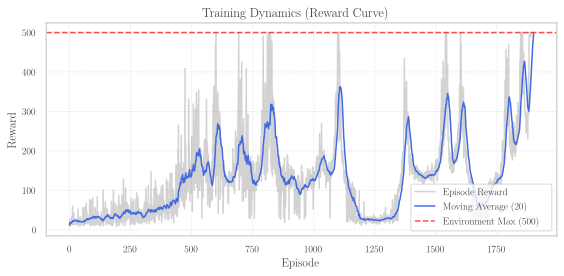

In [5]:
# =====================================================================
# A2C
# =====================================================================
NUM_ENVS = 4
NUM_STEPS = 128
GAMMA = 0.99
LR = 1e-3
TARGET_SCORE = 495
MAX_EPISODES = 1000
GAE_LAMBDA = 0.95
C_VAL = 0.05
C_ENT = 0.002
WINDOW_SIZE = 20

a2c_model = ActorCritic(state_dim=4, action_dim=2)
optimizer = torch.optim.Adam(a2c_model.parameters(), lr=LR)

# Векторизованная среда Gymnasium
envs = gym.make_vec("CartPole-v1", num_envs=NUM_ENVS, vectorization_mode="sync")
obs, _ = envs.reset(seed=42)

# Буферы метрик
env_rewards = np.zeros(NUM_ENVS)
a2c_episode_rewards = []
a2c_moving_averages = []

a2c_total_losses = []
a2c_actor_losses = []
a2c_critic_losses = []
a2c_entropy_losses = []

# Буферы шагов
obs_buf = torch.zeros((NUM_STEPS, NUM_ENVS, 4))
actions_buf = torch.zeros((NUM_STEPS, NUM_ENVS), dtype=torch.int64)
rewards_buf = torch.zeros((NUM_STEPS, NUM_ENVS))
dones_buf = torch.zeros((NUM_STEPS, NUM_ENVS))
values_buf = torch.zeros((NUM_STEPS, NUM_ENVS))
log_probs_buf = torch.zeros((NUM_STEPS, NUM_ENVS))
entropies_buf = torch.zeros((NUM_STEPS, NUM_ENVS))

for update in range(1, MAX_EPISODES + 1):
    # Синхронный сбор N шагов взаимодействия
    for step in range(NUM_STEPS):
        obs_t = torch.as_tensor(obs, dtype=torch.float32)
        obs_buf[step] = obs_t

        with torch.no_grad():
            logits, value = a2c_model(obs_t)
            dist = Categorical(logits=logits)
            action = dist.sample()

        actions_buf[step] = action
        values_buf[step] = value.squeeze(-1)
        log_probs_buf[step] = dist.log_prob(action)
        entropies_buf[step] = dist.entropy()

        next_obs, reward, terminated, truncated, _ = envs.step(action.numpy())
        done = np.logical_or(terminated, truncated)

        rewards_buf[step] = torch.as_tensor(reward, dtype=torch.float32)
        dones_buf[step] = torch.as_tensor(done, dtype=torch.float32)

        # Сбор реальной награды завершённых эпизодов
        env_rewards += reward
        for i, d in enumerate(done):
            if d:
                a2c_episode_rewards.append(env_rewards[i])
                env_rewards[i] = 0.0

        obs = next_obs

    # Вычисление GAE
    with torch.no_grad():
        next_obs_t = torch.as_tensor(obs, dtype=torch.float32)
        _, next_value = a2c_model(next_obs_t)
        next_val = next_value.squeeze(-1)

        advantages = torch.zeros_like(rewards_buf)
        last_gae = 0.0

        for t in reversed(range(NUM_STEPS)):
            if t == NUM_STEPS - 1:
                next_non_terminal = 1.0 - dones_buf[t]
                next_step_val = next_val
            else:
                next_non_terminal = 1.0 - dones_buf[t]
                next_step_val = values_buf[t + 1]

            delta = rewards_buf[t] + GAMMA * next_step_val * next_non_terminal - values_buf[t]
            last_gae = delta + GAMMA * GAE_LAMBDA * next_non_terminal * last_gae
            advantages[t] = last_gae

        returns = advantages + values_buf

    # Разворачивание в плоский батч
    b_obs = obs_buf.reshape(-1, 4)
    b_actions = actions_buf.reshape(-1)
    b_advantages = advantages.reshape(-1)
    b_returns = returns.reshape(-1)

    # Нормализация преимуществ
    b_advantages = (b_advantages - b_advantages.mean()) / (b_advantages.std() + 1e-8)

    # 4. Прямой проход с градиентами
    logits, values = a2c_model(b_obs)
    values = values.squeeze(-1)
    dist = Categorical(logits=logits)
    log_probs = dist.log_prob(b_actions)
    entropy = dist.entropy()

    actor_loss = -(log_probs * b_advantages.detach()).mean()
    critic_loss = F.smooth_l1_loss(values, b_returns)
    mean_entropy = entropy.mean()

    loss = actor_loss + C_VAL * critic_loss - C_ENT * mean_entropy

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(a2c_model.parameters(), max_norm=0.5)
    optimizer.step()

    a2c_total_losses.append(loss.item())
    a2c_actor_losses.append(actor_loss.item())
    a2c_critic_losses.append((C_VAL * critic_loss).item())
    a2c_entropy_losses.append((C_ENT * mean_entropy).item())

    if len(a2c_episode_rewards) >= 20:
        avg_score = np.mean(a2c_episode_rewards[-20:])
    else:
        avg_score = np.mean(a2c_episode_rewards) if a2c_episode_rewards else 0.0

    a2c_moving_averages.append(avg_score)

    if update % 100 == 0 or avg_score >= TARGET_SCORE:
        mean_tot = np.mean(a2c_total_losses[-20:])
        mean_act = np.mean(a2c_actor_losses[-20:])
        mean_crt = np.mean(a2c_critic_losses[-20:])
        mean_ent = np.mean(a2c_entropy_losses[-20:])

        print(
            f"Update {update:3d}/{MAX_EPISODES} | "
            f"Avg Reward (20): {avg_score:5.1f} | "
            f"Loss: {mean_tot:6.2f} "
            f"[Actor: {mean_act:6.2f}, "
            f"{C_VAL} * Critic: {mean_crt:6.2f}, "
            f"{-C_ENT} * Ent: {mean_ent:5.3f}]"
        )

    if avg_score >= TARGET_SCORE:
        print(f"\nA2C успешно решил среду на обновлении {update}! Средняя награда: {avg_score:.1f}")
        break

envs.close()

if len(a2c_episode_rewards) >= WINDOW_SIZE:
    # Кумулятивная сумма для расчета скользящего среднего
    cumsum = np.cumsum(np.insert(a2c_episode_rewards, 0, 0))
    moving_avg_episodes = (cumsum[WINDOW_SIZE:] - cumsum[:-WINDOW_SIZE]) / WINDOW_SIZE
    # Дополняем начало начальными средними, чтобы размер совпадал с числом эпизодов
    prefix = [np.mean(a2c_episode_rewards[:i]) for i in range(1, WINDOW_SIZE)]
    moving_avg_episodes = np.concatenate([prefix, moving_avg_episodes])
else:
    moving_avg_episodes = np.array(a2c_episode_rewards)


fig_reward, ax_reward = plt.subplots(figsize=(8, 4))

ax_reward.plot(a2c_episode_rewards, alpha=0.35, color='gray', label=r'Episode Reward')
ax_reward.plot(moving_avg_episodes, color='royalblue', linewidth=1.5, label=r'Moving Average (20)')
ax_reward.axhline(500, color='red', linestyle='--', alpha=0.7, label=r'Environment Max (500)')
ax_reward.set_title(r'Training Dynamics (Reward Curve)', fontsize=13, fontweight='bold')
ax_reward.set_xlabel(r'Episode')
ax_reward.set_ylabel(r'Reward')
ax_reward.grid(True, linestyle=':', alpha=0.6)
ax_reward.legend(loc='lower right')

plt.tight_layout()
plt.show()